# Homework 3 Optimization, Regularization & Activation Functions Solution by Ahad

#### Load Data Set

In [16]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

def load_mnist(batch_size=64, seed=42):
    transform = transforms.ToTensor()

    train_dataset = datasets.MNIST(
        root="./data",
        train=True,
        download=True,
        transform=transform
    )

    test_dataset = datasets.MNIST(
        root="./data",
        train=False,
        download=True,
        transform=transform
    )
    
    generator = torch.Generator().manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True, # useful for randomization in each epoch
        generator=generator
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False # need to keep false for consistent testing
    )

    return train_loader, test_loader

In [17]:
train_loader, test_loader = load_mnist()

#### Inspect Data

In [19]:
# sample size
print("Training samples:", len(train_loader.dataset))
print("Test samples:", len(test_loader.dataset))

# look at images in a batch
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Labels:", labels)

print("Min pixel value:", images.min().item())
print("Max pixel value:", images.max().item())

Training samples: 60000
Test samples: 10000
Images shape: torch.Size([64, 1, 28, 28])
Labels shape: torch.Size([64])
Labels: tensor([2, 5, 4, 0, 1, 6, 4, 2, 2, 2, 6, 3, 7, 2, 0, 7, 3, 2, 6, 3, 4, 1, 3, 2,
        3, 2, 3, 5, 6, 0, 4, 5, 8, 8, 0, 5, 2, 5, 4, 7, 1, 0, 8, 3, 6, 1, 3, 9,
        4, 9, 2, 2, 6, 8, 6, 4, 4, 6, 1, 0, 8, 2, 4, 7])
Min pixel value: 0.0
Max pixel value: 1.0


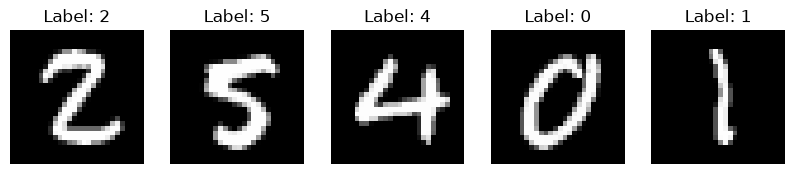

In [20]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 5, figsize=(10, 2))

for i, ax in enumerate(axes):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis("off")

plt.show()

#### Generate Reproducible Model and Loss Function (Cross Entropy)

In [26]:
# Input -> Hidden Layer - > Output
# How many hidden layers do I want?

# 28 x 28 image size means flattened value is 784 and there are 10 output values 0-9

import torch
import torch.nn as nn

def initialize_model(activation_fn=nn.ReLU, dropout_p=0.0):
    torch.manual_seed(42)

    model = nn.Sequential(
        nn.Flatten(),

        nn.Linear(784, 128),
        activation_fn(),
        nn.Dropout(dropout_p),

        nn.Linear(128, 64),
        activation_fn(),
        nn.Dropout(dropout_p),

        nn.Linear(64, 10)
    )

    return model

loss_function = nn.CrossEntropyLoss()

In [27]:
model = initialize_model()
print(model)
print(loss_function)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): ReLU()
  (3): Dropout(p=0.0, inplace=False)
  (4): Linear(in_features=128, out_features=64, bias=True)
  (5): ReLU()
  (6): Dropout(p=0.0, inplace=False)
  (7): Linear(in_features=64, out_features=10, bias=True)
)
CrossEntropyLoss()


#### Batch Gradient Descent

In [33]:
model = initialize_model()
batch_gd_loader = DataLoader(
    train_loader.dataset,
    batch_size=len(train_loader.dataset),
    shuffle=False
)

batch_optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01    
)

In [34]:
epochs = 200
batch_losses = []

for epoch in range(epochs):
    model.train() # Switch to training mode
    
    for images, labels in batch_gd_loader:
        batch_optimizer.zero_grad() # Reset the gradients for each batch
        
        logits = model(images) # Forward propagation
        
        loss = loss_function(logits, labels) # calculate loss using logits
        
        loss.backward() # Compute gradient of the loss
        batch_optimizer.step() # Apply the new updated parameters
    
    batch_losses.append(loss.item()) # Loss is the average cross-entropy loss over all 60,000 training images for that epoch
    print(f"Epoch {epoch+1}: Loss = {loss.item():.4f}")

Epoch 1: Loss = 2.3139
Epoch 2: Loss = 2.3135
Epoch 3: Loss = 2.3130
Epoch 4: Loss = 2.3126
Epoch 5: Loss = 2.3121
Epoch 6: Loss = 2.3117
Epoch 7: Loss = 2.3113
Epoch 8: Loss = 2.3108
Epoch 9: Loss = 2.3104
Epoch 10: Loss = 2.3100
Epoch 11: Loss = 2.3096
Epoch 12: Loss = 2.3091
Epoch 13: Loss = 2.3087
Epoch 14: Loss = 2.3083
Epoch 15: Loss = 2.3078
Epoch 16: Loss = 2.3074
Epoch 17: Loss = 2.3070
Epoch 18: Loss = 2.3066
Epoch 19: Loss = 2.3061
Epoch 20: Loss = 2.3057
Epoch 21: Loss = 2.3053
Epoch 22: Loss = 2.3049
Epoch 23: Loss = 2.3045
Epoch 24: Loss = 2.3041
Epoch 25: Loss = 2.3036
Epoch 26: Loss = 2.3032
Epoch 27: Loss = 2.3028
Epoch 28: Loss = 2.3024
Epoch 29: Loss = 2.3020
Epoch 30: Loss = 2.3016
Epoch 31: Loss = 2.3011
Epoch 32: Loss = 2.3007
Epoch 33: Loss = 2.3003
Epoch 34: Loss = 2.2999
Epoch 35: Loss = 2.2995
Epoch 36: Loss = 2.2991
Epoch 37: Loss = 2.2987
Epoch 38: Loss = 2.2983
Epoch 39: Loss = 2.2978
Epoch 40: Loss = 2.2974
Epoch 41: Loss = 2.2970
Epoch 42: Loss = 2.2966
E

#### Stochastic Gradient Descent

In [36]:
model = initialize_model()
sgd_optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01    
)

sgd_losses = []
train_loader, test_loader = load_mnist(batch_size=64, seed=42) # Keep same seed as TA instructed for each run

for epoch in range(epochs):
    model.train()
    total_loss = 0
    
    for images, labels in train_loader:
        sgd_optimizer.zero_grad() 
        
        logits = model(images)
        
        loss = loss_function(logits, labels)
        
        loss.backward()
        sgd_optimizer.step()
        
        total_loss += loss.item() * images.size(0) # get the total loss across all 60k training. Not all batches maybe be the exact same size especially at the end
    
    epoch_loss = total_loss / len(train_loader.dataset)
    sgd_losses.append(epoch_loss)
    print(f"Epoch {epoch+1}: Loss = {epoch_loss:.4f}")

Epoch 1: Loss = 1.6662
Epoch 2: Loss = 0.5509
Epoch 3: Loss = 0.3938
Epoch 4: Loss = 0.3458
Epoch 5: Loss = 0.3161
Epoch 6: Loss = 0.2936
Epoch 7: Loss = 0.2747
Epoch 8: Loss = 0.2584
Epoch 9: Loss = 0.2436
Epoch 10: Loss = 0.2311
Epoch 11: Loss = 0.2189
Epoch 12: Loss = 0.2083
Epoch 13: Loss = 0.1979
Epoch 14: Loss = 0.1887
Epoch 15: Loss = 0.1799
Epoch 16: Loss = 0.1720
Epoch 17: Loss = 0.1644
Epoch 18: Loss = 0.1571
Epoch 19: Loss = 0.1506
Epoch 20: Loss = 0.1445
Epoch 21: Loss = 0.1386
Epoch 22: Loss = 0.1334
Epoch 23: Loss = 0.1286
Epoch 24: Loss = 0.1237
Epoch 25: Loss = 0.1195
Epoch 26: Loss = 0.1148
Epoch 27: Loss = 0.1109
Epoch 28: Loss = 0.1073
Epoch 29: Loss = 0.1037
Epoch 30: Loss = 0.1005
Epoch 31: Loss = 0.0974
Epoch 32: Loss = 0.0942
Epoch 33: Loss = 0.0911
Epoch 34: Loss = 0.0883
Epoch 35: Loss = 0.0859
Epoch 36: Loss = 0.0833
Epoch 37: Loss = 0.0810
Epoch 38: Loss = 0.0784
Epoch 39: Loss = 0.0764
Epoch 40: Loss = 0.0742
Epoch 41: Loss = 0.0721
Epoch 42: Loss = 0.0700
E

#### Momentum Optimization

In [37]:
model = initialize_model()
momentum_optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01,
    momentum=0.9    
)

momentum_losses = []
train_loader, test_loader = load_mnist(batch_size=64, seed=42)

for epoch in range(epochs):
    model.train()
    total_loss = 0
        
    for images, labels in train_loader:
        momentum_optimizer.zero_grad()
        
        logits = model(images)
                
        loss = loss_function(logits, labels)
        
        loss.backward()
        momentum_optimizer.step()
        total_loss += loss.item() * images.size(0)
        
    epoch_loss = total_loss / len(train_loader.dataset)
    momentum_losses.append(epoch_loss)
    print(f"Epoch {epoch+1}: Loss = {epoch_loss:.4f}")   
        

Epoch 1: Loss = 0.5331
Epoch 2: Loss = 0.1966
Epoch 3: Loss = 0.1343
Epoch 4: Loss = 0.1006
Epoch 5: Loss = 0.0804
Epoch 6: Loss = 0.0664
Epoch 7: Loss = 0.0550
Epoch 8: Loss = 0.0462
Epoch 9: Loss = 0.0396
Epoch 10: Loss = 0.0342
Epoch 11: Loss = 0.0283
Epoch 12: Loss = 0.0250
Epoch 13: Loss = 0.0209
Epoch 14: Loss = 0.0167
Epoch 15: Loss = 0.0147
Epoch 16: Loss = 0.0123
Epoch 17: Loss = 0.0096
Epoch 18: Loss = 0.0084
Epoch 19: Loss = 0.0074
Epoch 20: Loss = 0.0059
Epoch 21: Loss = 0.0050
Epoch 22: Loss = 0.0040
Epoch 23: Loss = 0.0035
Epoch 24: Loss = 0.0027
Epoch 25: Loss = 0.0022
Epoch 26: Loss = 0.0018
Epoch 27: Loss = 0.0017
Epoch 28: Loss = 0.0015
Epoch 29: Loss = 0.0013
Epoch 30: Loss = 0.0012
Epoch 31: Loss = 0.0011
Epoch 32: Loss = 0.0011
Epoch 33: Loss = 0.0010
Epoch 34: Loss = 0.0009
Epoch 35: Loss = 0.0009
Epoch 36: Loss = 0.0008
Epoch 37: Loss = 0.0008
Epoch 38: Loss = 0.0007
Epoch 39: Loss = 0.0007
Epoch 40: Loss = 0.0007
Epoch 41: Loss = 0.0006
Epoch 42: Loss = 0.0006
E

#### Adam Optimization

In [38]:
model = initialize_model()
adam_optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

adam_losses = []
train_loader, test_loader = load_mnist(batch_size=64, seed=42)

for epoch in range(epochs):
    model.train()
    total_loss = 0
        
    for images, labels in train_loader:
        adam_optimizer.zero_grad()
        
        logits = model(images)
                
        loss = loss_function(logits, labels)
        
        loss.backward()
        adam_optimizer.step()
        total_loss += loss.item() * images.size(0)
        
    epoch_loss = total_loss / len(train_loader.dataset)
    adam_losses.append(epoch_loss)
    print(f"Epoch {epoch+1}: Loss = {epoch_loss:.4f}")   
        

Epoch 1: Loss = 0.3391
Epoch 2: Loss = 0.1390
Epoch 3: Loss = 0.0950
Epoch 4: Loss = 0.0715
Epoch 5: Loss = 0.0560
Epoch 6: Loss = 0.0445
Epoch 7: Loss = 0.0370
Epoch 8: Loss = 0.0303
Epoch 9: Loss = 0.0250
Epoch 10: Loss = 0.0210
Epoch 11: Loss = 0.0177
Epoch 12: Loss = 0.0170
Epoch 13: Loss = 0.0173
Epoch 14: Loss = 0.0134
Epoch 15: Loss = 0.0124
Epoch 16: Loss = 0.0103
Epoch 17: Loss = 0.0100
Epoch 18: Loss = 0.0084
Epoch 19: Loss = 0.0094
Epoch 20: Loss = 0.0103
Epoch 21: Loss = 0.0086
Epoch 22: Loss = 0.0086
Epoch 23: Loss = 0.0062
Epoch 24: Loss = 0.0078
Epoch 25: Loss = 0.0064
Epoch 26: Loss = 0.0067
Epoch 27: Loss = 0.0058
Epoch 28: Loss = 0.0069
Epoch 29: Loss = 0.0086
Epoch 30: Loss = 0.0061
Epoch 31: Loss = 0.0080
Epoch 32: Loss = 0.0036
Epoch 33: Loss = 0.0086
Epoch 34: Loss = 0.0065
Epoch 35: Loss = 0.0029
Epoch 36: Loss = 0.0048
Epoch 37: Loss = 0.0071
Epoch 38: Loss = 0.0037
Epoch 39: Loss = 0.0081
Epoch 40: Loss = 0.0031
Epoch 41: Loss = 0.0054
Epoch 42: Loss = 0.0031
E

#### Plots of the Optimizers

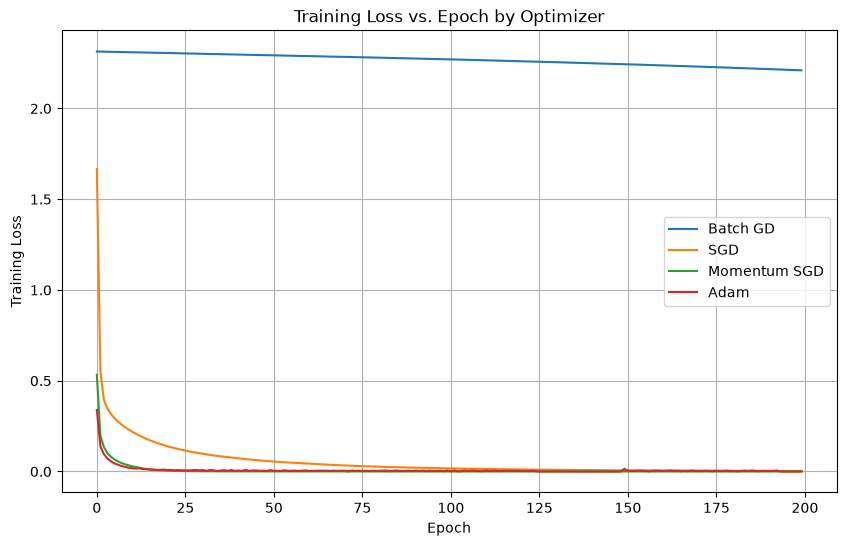

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(batch_losses, label="Batch GD")
plt.plot(sgd_losses, label="SGD")
plt.plot(momentum_losses, label="Momentum SGD")
plt.plot(adam_losses, label="Adam")

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss vs. Epoch by Optimizer")
plt.legend()
plt.grid(True)
plt.show()

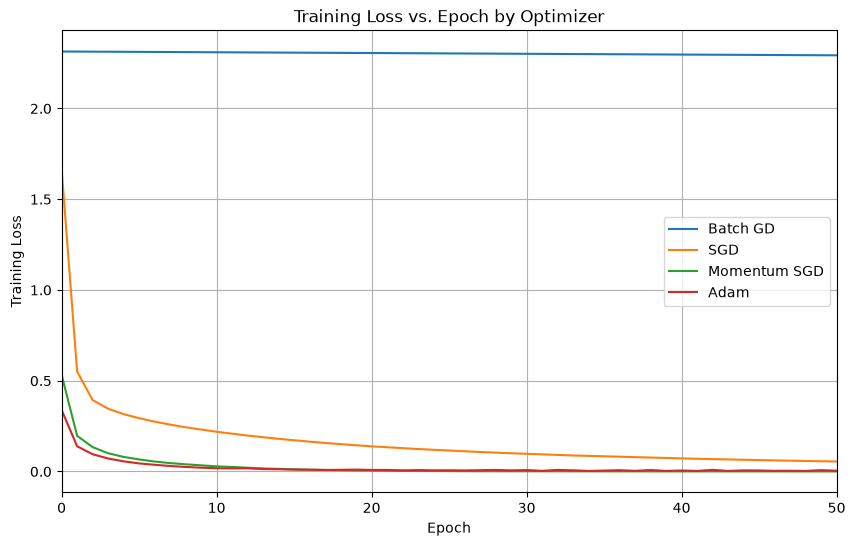

In [58]:
plt.figure(figsize=(10, 6))

plt.plot(batch_losses, label="Batch GD")
plt.plot(sgd_losses, label="SGD")
plt.plot(momentum_losses, label="Momentum SGD")
plt.plot(adam_losses, label="Adam")

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss vs. Epoch by Optimizer")
plt.legend()
plt.grid(True)
plt.xlim(0, 50)
plt.show()

Adam Converges just a bit faster than Momentum SGD

### 2. Regularization
#### I will use Adam as it performed the best over 200 epochs and will hold the architecture the same as well

In [43]:
# Create the train/validate split on the MNIST data set
from torch.utils.data import random_split

train_dataset, val_dataset = random_split(
    dataset=train_loader.dataset,
    lengths=[50000,10000],
    generator=torch.Generator().manual_seed(42)
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

Training samples: 50000
Validation samples: 10000


#### Reproducible Function for Regularization

In [46]:
def train_regularization(reg_type, reg_strength, epochs):
    train_reg_loader = DataLoader(train_dataset,batch_size=64,shuffle=True,generator=torch.Generator().manual_seed(42))

    val_reg_loader = DataLoader(val_dataset,batch_size=64,shuffle=False)
    
    train_eval_loader = DataLoader(train_dataset, batch_size=64, shuffle=False)
    
    if reg_type == "dropout":
        model = initialize_model(dropout_p=reg_strength)
    else:
        model = initialize_model()
        
    if reg_type == "l2":
        adam_optimizer = torch.optim.Adam(model.parameters(),lr=0.001, weight_decay=reg_strength)
    else:
        adam_optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
        
    train_losses = []
    train_accuracies = []

    val_losses = []
    val_accuracies = []

    for epoch in range(epochs):
        model.train()
            
        for images, labels in train_reg_loader:
            adam_optimizer.zero_grad()
            
            logits = model(images)
            
            loss = loss_function(logits, labels)
            
            if reg_type == "l1":
                l1_penalty = sum(p.abs().sum() for p in model.parameters() if p.ndim > 1)
                training_loss = loss + reg_strength * l1_penalty
            else:
                training_loss = loss
            
            training_loss.backward()
            adam_optimizer.step()
            
        
        model.eval() # model done training time to check against training data and validation
        
        train_total_loss = 0
        train_correct = 0

        with torch.no_grad(): # How well did the model learned the data it was trained on.
            for images, labels in train_eval_loader:
                logits = model(images)
                loss = loss_function(logits, labels)

                train_total_loss += loss.item() * images.size(0)

                predictions = torch.argmax(logits, dim=1)
                train_correct += (predictions == labels).sum().item()

        train_losses.append(train_total_loss / len(train_eval_loader.dataset))
        train_accuracies.append(train_correct / len(train_eval_loader.dataset))
        
        total_validation_loss = 0
        correct_predictions = 0
          
        with torch.no_grad(): # No more gradients needed
            for images, labels in val_reg_loader: # How well does the learning transfers to unseen data
                logits = model(images)
                loss = loss_function(logits, labels)
                
                total_validation_loss += loss.item() * images.size(0)
                
                predictions = torch.argmax(logits, dim=1)
                
                correct_predictions += (predictions == labels).sum().item()
                
            accuracy = correct_predictions / len(val_reg_loader.dataset)
            avg_validation_loss = total_validation_loss / len(val_reg_loader.dataset)
            val_losses.append(avg_validation_loss)
            val_accuracies.append(accuracy)
    
    return train_losses, train_accuracies, val_losses, val_accuracies, model

In [47]:
no_reg_train_loss, no_reg_train_accuracies, no_reg_val_losses, no_reg_val_accuracies, no_reg_model = train_regularization("none", 0, 200)
dropout_train_loss, dropout_train_accuracies, dropout_val_losses, dropout_val_accuracies, dropout_model = train_regularization("dropout", 0.5, 200)
l1_train_loss, l1_train_accuracies, l1_val_losses, l1_val_accuracies, l1_model = train_regularization("l1", 0.00001, 200)
l2_train_loss, l2_train_accuracies, l2_val_losses, l2_val_accuracies, l2_model = train_regularization("l2", 0.0001, 200)


In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(batch_losses, label="Batch GD")
plt.plot(sgd_losses, label="SGD")
plt.plot(momentum_losses, label="Momentum SGD")
plt.plot(adam_losses, label="Adam")

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss vs. Epoch by Optimizer")
plt.legend()
plt.grid(True)
plt.show()

#### Training Loss vs Epoch

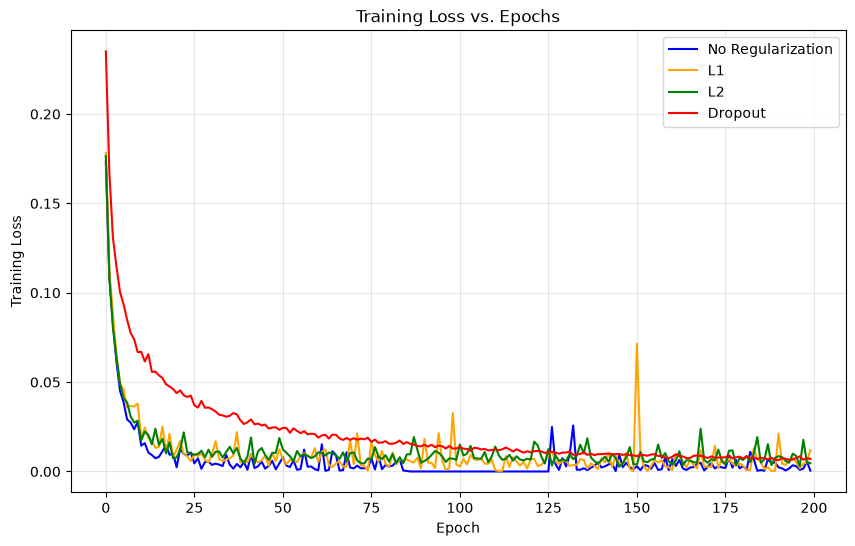

In [48]:
plt.figure(figsize=(10, 6))

plt.plot(no_reg_train_loss, label="No Regularization", color="blue")
plt.plot(l1_train_loss, label="L1", color="orange")
plt.plot(l2_train_loss, label="L2", color="green")
plt.plot(dropout_train_loss, label="Dropout", color="red")

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss vs. Epochs")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### Validation Loss vs. Epochs

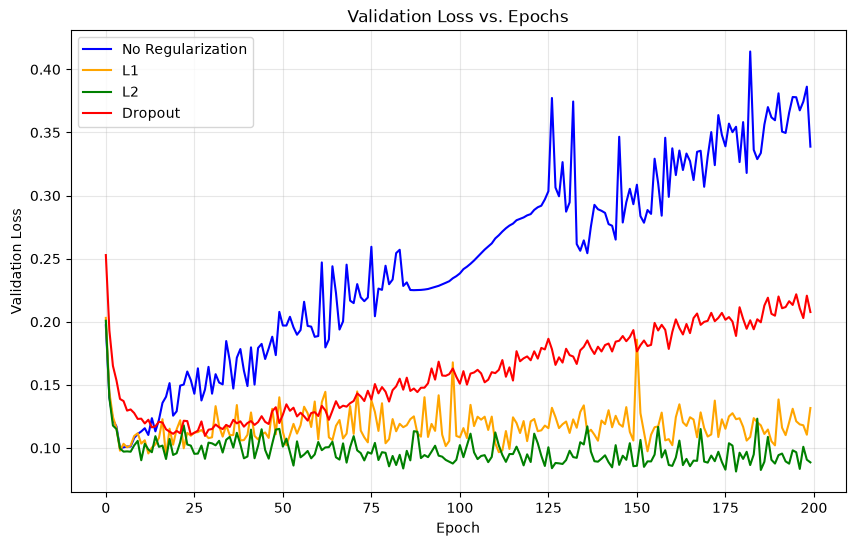

In [49]:
plt.figure(figsize=(10, 6))

plt.plot(no_reg_val_losses, label="No Regularization", color="blue")
plt.plot(l1_val_losses, label="L1", color="orange")
plt.plot(l2_val_losses, label="L2", color="green")
plt.plot(dropout_val_losses, label="Dropout", color="red")

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss vs. Epochs")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### Training Accuracy vs. Epochs

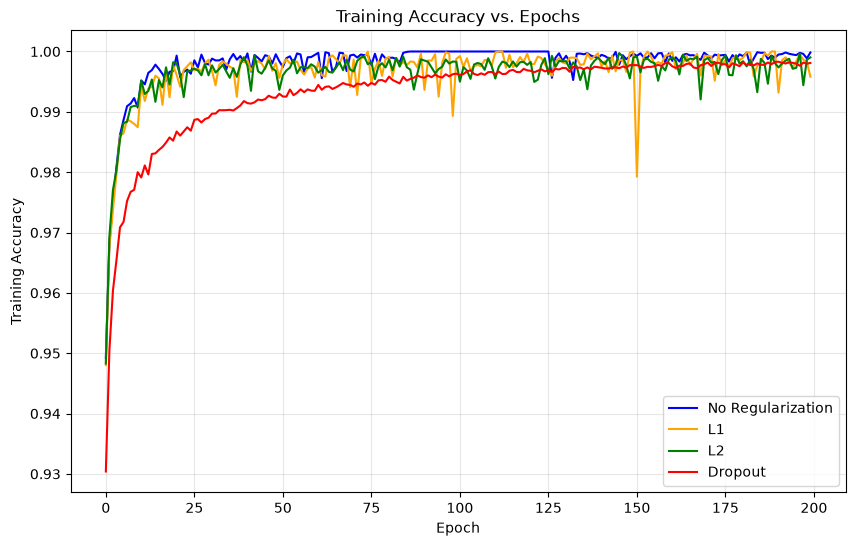

In [50]:
plt.figure(figsize=(10, 6))

plt.plot(no_reg_train_accuracies, label="No Regularization", color="blue")
plt.plot(l1_train_accuracies, label="L1", color="orange")
plt.plot(l2_train_accuracies, label="L2", color="green")
plt.plot(dropout_train_accuracies, label="Dropout", color="red")

plt.xlabel("Epoch")
plt.ylabel("Training Accuracy")
plt.title("Training Accuracy vs. Epochs")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### Validation Accuracy vs. Epochs

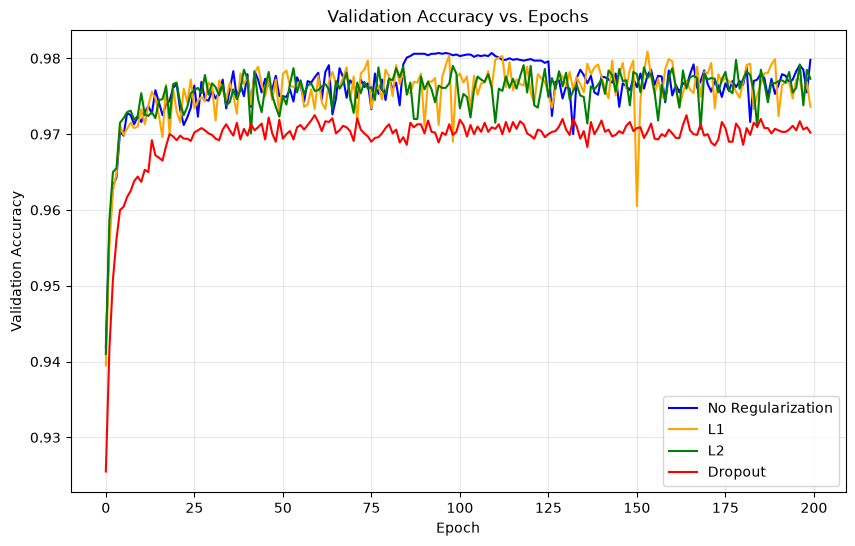

In [51]:
plt.figure(figsize=(10, 6))

plt.plot(no_reg_val_accuracies, label="No Regularization", color="blue")
plt.plot(l1_val_accuracies, label="L1", color="orange")
plt.plot(l2_val_accuracies, label="L2", color="green")
plt.plot(dropout_val_accuracies, label="Dropout", color="red")

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy vs. Epochs")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Activation Functions

In [52]:
def train_activation_functions(activation_fn, epochs):
    train_reg_loader = DataLoader(train_dataset,batch_size=64,shuffle=True,generator=torch.Generator().manual_seed(42))

    val_reg_loader = DataLoader(val_dataset,batch_size=64,shuffle=False)
    
    train_eval_loader = DataLoader(train_dataset, batch_size=64, shuffle=False)
    

    model = initialize_model(activation_fn=activation_fn)

    adam_optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
        
    train_losses = []
    train_accuracies = []

    val_losses = []
    val_accuracies = []

    for epoch in range(epochs):
        model.train()
            
        for images, labels in train_reg_loader:
            adam_optimizer.zero_grad()
            
            logits = model(images)
            
            loss = loss_function(logits, labels)
            
            loss.backward()
            adam_optimizer.step()
            
        
        model.eval() # model done training time to check against training data and validation
        
        train_total_loss = 0
        train_correct = 0

        with torch.no_grad(): # How well did the model learned the data it was trained on.
            for images, labels in train_eval_loader:
                logits = model(images)
                loss = loss_function(logits, labels)

                train_total_loss += loss.item() * images.size(0)

                predictions = torch.argmax(logits, dim=1)
                train_correct += (predictions == labels).sum().item()

        train_losses.append(train_total_loss / len(train_eval_loader.dataset))
        train_accuracies.append(train_correct / len(train_eval_loader.dataset))
        
        total_validation_loss = 0
        correct_predictions = 0
          
        with torch.no_grad(): # No more gradients needed
            for images, labels in val_reg_loader: # How well does the learning transfers to unseen data
                logits = model(images)
                loss = loss_function(logits, labels)
                
                total_validation_loss += loss.item() * images.size(0)
                
                predictions = torch.argmax(logits, dim=1)
                
                correct_predictions += (predictions == labels).sum().item()
                
            accuracy = correct_predictions / len(val_reg_loader.dataset)
            avg_validation_loss = total_validation_loss / len(val_reg_loader.dataset)
            val_losses.append(avg_validation_loss)
            val_accuracies.append(accuracy)
        
        print(f"{activation_fn.__name__}: Epoch {epoch + 1}/{epochs} completed", flush=True)
    
    return train_losses, train_accuracies, val_losses, val_accuracies, model

In [53]:
# Switching to 50 since the other experiments for Regularization took quite some time
relu_results = train_activation_functions(nn.ReLU, 100)
sigmoid_results = train_activation_functions(nn.Sigmoid, 100)
tanh_results = train_activation_functions(nn.Tanh, 100)

ReLU: Epoch 1/100 completed
ReLU: Epoch 2/100 completed
ReLU: Epoch 3/100 completed
ReLU: Epoch 4/100 completed
ReLU: Epoch 5/100 completed
ReLU: Epoch 6/100 completed
ReLU: Epoch 7/100 completed
ReLU: Epoch 8/100 completed
ReLU: Epoch 9/100 completed
ReLU: Epoch 10/100 completed
ReLU: Epoch 11/100 completed
ReLU: Epoch 12/100 completed
ReLU: Epoch 13/100 completed
ReLU: Epoch 14/100 completed
ReLU: Epoch 15/100 completed
ReLU: Epoch 16/100 completed
ReLU: Epoch 17/100 completed
ReLU: Epoch 18/100 completed
ReLU: Epoch 19/100 completed
ReLU: Epoch 20/100 completed
ReLU: Epoch 21/100 completed
ReLU: Epoch 22/100 completed
ReLU: Epoch 23/100 completed
ReLU: Epoch 24/100 completed
ReLU: Epoch 25/100 completed
ReLU: Epoch 26/100 completed
ReLU: Epoch 27/100 completed
ReLU: Epoch 28/100 completed
ReLU: Epoch 29/100 completed
ReLU: Epoch 30/100 completed
ReLU: Epoch 31/100 completed
ReLU: Epoch 32/100 completed
ReLU: Epoch 33/100 completed
ReLU: Epoch 34/100 completed
ReLU: Epoch 35/100 comp

##### Training Loss vs Epoch

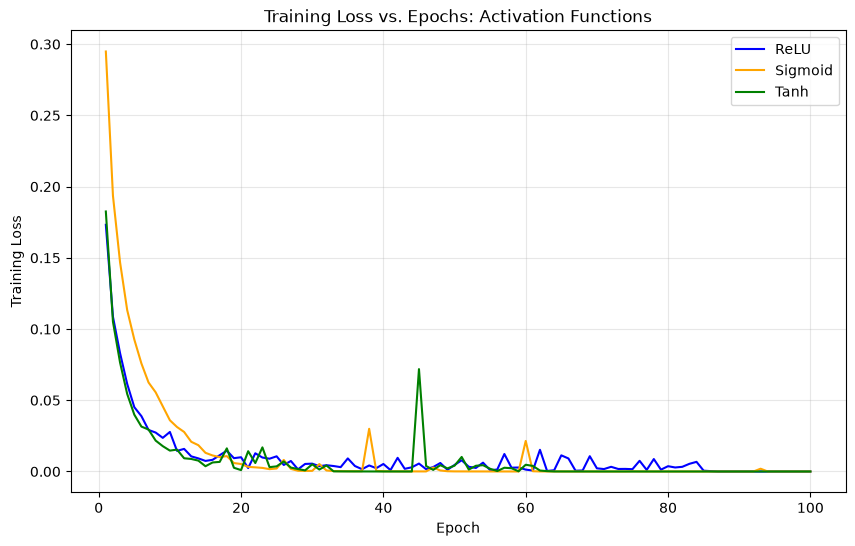

In [54]:
plt.figure(figsize=(10, 6))

plt.plot(range(1, 101), relu_results[0], label="ReLU", color="blue")
plt.plot(range(1, 101), sigmoid_results[0], label="Sigmoid", color="orange")
plt.plot(range(1, 101), tanh_results[0], label="Tanh", color="green")

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss vs. Epochs: Activation Functions")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

##### Training Accuracy vs. Epochs

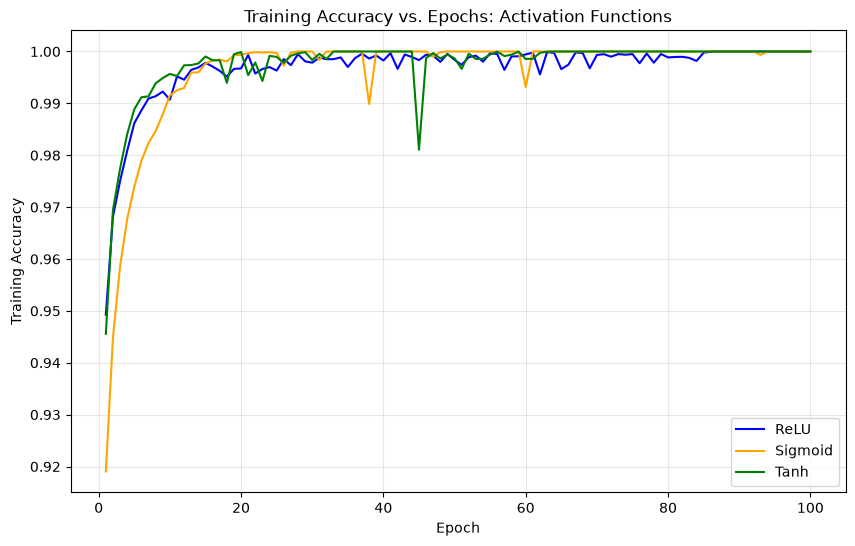

In [55]:
plt.figure(figsize=(10, 6))

plt.plot(range(1, 101), relu_results[1], label="ReLU", color="blue")
plt.plot(range(1, 101), sigmoid_results[1], label="Sigmoid", color="orange")
plt.plot(range(1, 101), tanh_results[1], label="Tanh", color="green")

plt.xlabel("Epoch")
plt.ylabel("Training Accuracy")
plt.title("Training Accuracy vs. Epochs: Activation Functions")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

##### Validation Loss vs. Epochs

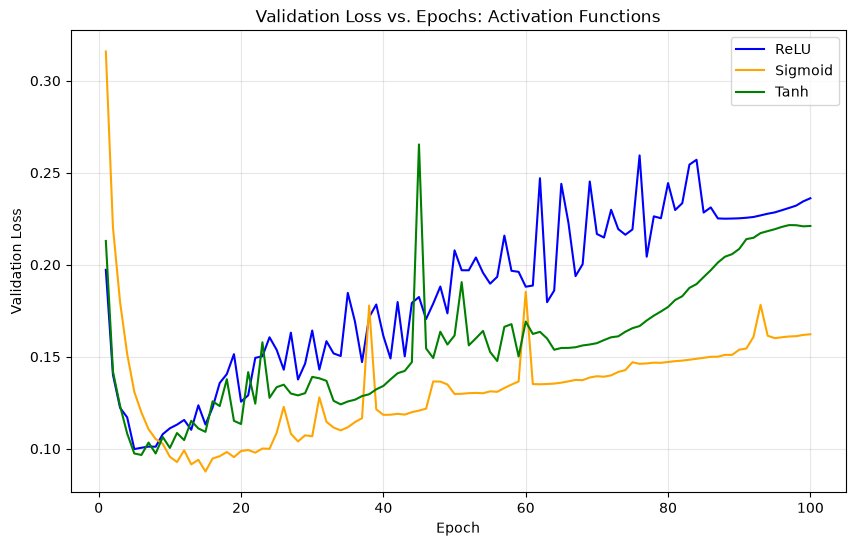

In [56]:
plt.figure(figsize=(10, 6))

plt.plot(range(1, 101), relu_results[2], label="ReLU", color="blue")
plt.plot(range(1, 101), sigmoid_results[2], label="Sigmoid", color="orange")
plt.plot(range(1, 101), tanh_results[2], label="Tanh", color="green")

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss vs. Epochs: Activation Functions")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

##### Validation Accuracy vs. Epochs

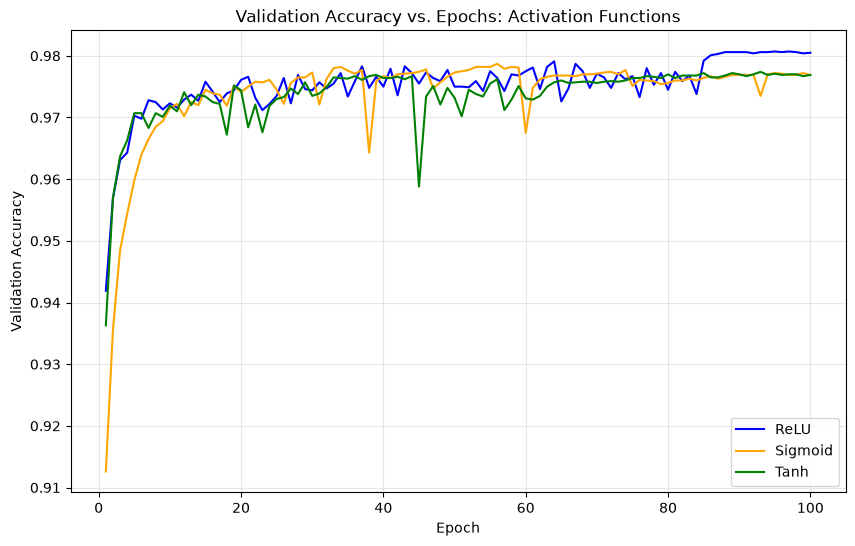

In [57]:
plt.figure(figsize=(10, 6))

plt.plot(range(1, 101), relu_results[3], label="ReLU", color="blue")
plt.plot(range(1, 101), sigmoid_results[3], label="Sigmoid", color="orange")
plt.plot(range(1, 101), tanh_results[3], label="Tanh", color="green")

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy vs. Epochs: Activation Functions")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

##### Looking at L1 and L2 weights

In [59]:
for name, model in [("No Reg", no_reg_model),
                    ("L1", l1_model),
                    ("L2", l2_model)]:
    l1_norm = 0
    l2_squared = 0
    for p in model.parameters():
        if p.ndim > 1:
            l1_norm += p.abs().sum().item()
            l2_squared += p.square().sum().item()

    print(f"{name}: L1 Norm = {l1_norm:.4f}, L2 Norm = {l2_squared**0.5:.4f}")

No Reg: L1 Norm = 24449.4323, L2 Norm = 102.9662
L1: L1 Norm = 2726.6391, L2 Norm = 31.6400
L2: L1 Norm = 3398.1760, L2 Norm = 22.5069
